# Sığorta ödənişlərinin təhlili
Sığorta haqları və ödənişlər ilin əvvəlindən yığılan məbləğlərdir və **min AZN** ilə göstərilir. Daha yeni hesabatdakı mövcud məbləğlərə üstünlük verilir. Layihədə təmizlənmiş CSV faylları istifadə olunur.

Model məlum sığorta haqları əsasında ödənişləri təxmin edir. Bu, gələcək ödənişlərin proqnozu deyil. Tarixi məlumatlara düzəlişlər nəticələrin qiymətləndirilməsinə təsir edə bilər.

## Kitabxanaların idxalı

In [1]:
from pathlib import Path
from textwrap import fill

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="white")
pd.set_option("display.max_columns", None)
MONTHS_AZ = [
    "Yan", "Fev", "Mar", "Apr", "May", "İyn",
    "İyl", "Avq", "Sen", "Okt", "Noy", "Dek",
]


## Məlumatların yüklənməsi və təmizlənməsi

In [2]:
# Həm layihə kökündən, həm notebooks qovluğundan işləyir.
PROJECT_DIR = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents]
    if (folder / "app.py").is_file() and (folder / "data").is_dir()
)
DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(exist_ok=True)
FILES = [DATA_DIR / f"insurance_2016_{year}.csv" for year in [2025, 2026]]
KEYS = ["company", "year", "month"]

data = pd.concat(
    [pd.read_csv(path, parse_dates=["date"]) for path in FILES],
    ignore_index=True,
)
# Hər şirkət və dövr üçün daha yeni mövcud məbləğ seçilir.
df = data.groupby(KEYS, as_index=False).last()
print("Təmizləmədən əvvəl çatışmayan dəyərlər:")
display(df.isna().sum().to_frame("missing"))
df = df.dropna(subset=["premiums"]).reset_index(drop=True)
print(f"{len(df):,} sətir; {df['company'].nunique()} şirkət")


Təmizləmədən əvvəl çatışmayan dəyərlər:


,missing
company,0
year,0
month,0
claims,0
premiums,18
date,0


3,186 sətir; 29 şirkət


## Məlumatların ilkin təhlili

In [3]:
display(df.head())
display(df[["premiums", "claims"]].describe())
print("Sıfır məbləğlər:")
display(df[["premiums", "claims"]].eq(0).sum().to_frame("zeros"))
print("Şirkətlərin yığılan ödənişləri üzrə statistika:")
display(df.groupby("company")["claims"].agg(["mean", "median", "count"]))


,company,year,month,claims,premiums,date
0,"""Aqrar Sığorta"" Açıq Səhmdar Cəmiyyəti",2016,1,0.0,0.0,2016-01-01
1,"""Aqrar Sığorta"" Açıq Səhmdar Cəmiyyəti",2016,2,0.0,0.0,2016-02-01
2,"""Aqrar Sığorta"" Açıq Səhmdar Cəmiyyəti",2016,3,0.0,0.0,2016-03-01
3,"""Aqrar Sığorta"" Açıq Səhmdar Cəmiyyəti",2016,4,0.0,0.0,2016-04-01
4,"""Aqrar Sığorta"" Açıq Səhmdar Cəmiyyəti",2016,5,0.0,0.0,2016-05-01


,premiums,claims
count,3186.000000,3186.000000
mean,21247.217719,10076.987213
std,58034.120816,36880.842658
min,0.000000,0.000000
25%,324.923480,35.462958
50%,4908.499400,1453.199825
75%,15548.720100,6018.890218
max,679749.571320,561072.822380


Sıfır məbləğlər:


,zeros
premiums,617
claims,635


Şirkətlərin yığılan ödənişləri üzrə statistika:


,mean,median,count
company,,,
"""Aqrar Sığorta"" Açıq Səhmdar Cəmiyyəti",951.102903,0.000000,127
"""Meqa Həyat Sığorta"" Açıq Səhmdar Cəmiyyəti",757.180879,8.093360,77
"""Naxçıvansığorta"" Açıq Səhmdar Cəmiyyəti",92.601851,3.259950,128
"""Xalq Həyat"" Sığorta Şirkəti Açıq Səhmdar Cəmiyyəti",940.489644,56.610910,128
Azərbaycan Respublikası Dövlət Sığorta Kommersiya Şirkəti,10233.590343,7919.518000,128
“A-Qroup Sığorta Şirkəti” Açıq Səhmdar Cəmiyyəti,5489.018633,5251.166595,128
“AXA MBASK” Sığorta Şirkəti Açıq Səhmdar Cəmiyyəti,3322.958229,2266.558860,76
“Alfa Sığorta” Açıq Səhmdar Cəmiyyəti,102.995692,0.000000,75
“Amrah Sığorta” Açıq Səhmdar Cəmiyyəti,114.359824,48.825980,76


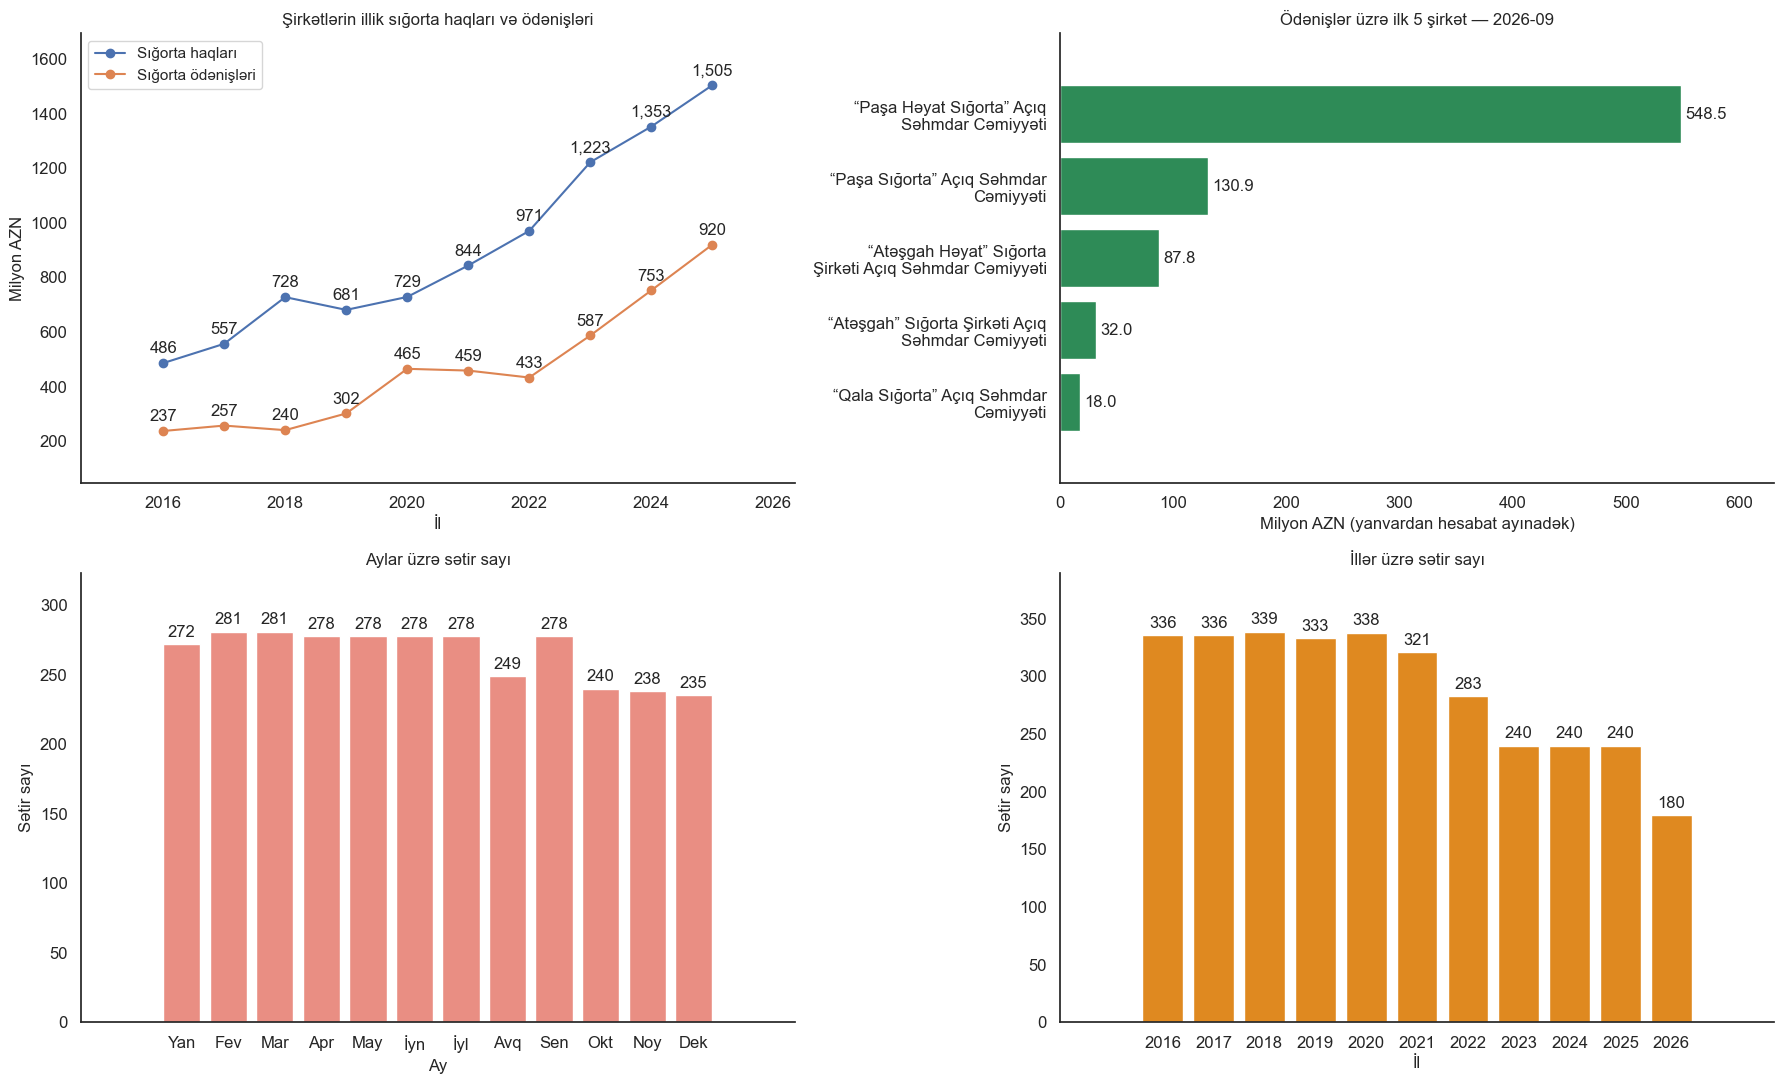

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(18, 11))

# Dekabr bütün ili əhatə edir; natamam illər daxil edilmir.
annual = (
    df.loc[df["month"].eq(12)]
    .groupby("year")[["premiums", "claims"]].sum(min_count=1) / 1_000
)
annual.rename(columns={
    "premiums": "Sığorta haqları", "claims": "Sığorta ödənişləri",
}).plot(marker="o", ax=axes[0, 0])
axes[0, 0].set(
    title="Şirkətlərin illik sığorta haqları və ödənişləri",
    xlabel="İl", ylabel="Milyon AZN",
)
for line in axes[0, 0].lines:
    for x, y in zip(line.get_xdata(), line.get_ydata()):
        axes[0, 0].annotate(
            f"{y:,.0f}", (x, y), xytext=(0, 7),
            textcoords="offset points", ha="center", fontsize=12,
        )

latest_date = df["date"].max()
top = df.loc[df["date"].eq(latest_date)].nlargest(5, "claims")
top = top.sort_values("claims")
axes[0, 1].barh(
    [fill(name, 30) for name in top["company"]],
    top["claims"] / 1_000, color="seagreen",
)
axes[0, 1].set(
    title=f"Ödənişlər üzrə ilk 5 şirkət — {latest_date:%Y-%m}",
    xlabel="Milyon AZN (yanvardan hesabat ayınadək)",
)

sns.countplot(
    data=df, x="month", order=range(1, 13),
    ax=axes[1, 0], color="salmon",
)
axes[1, 0].set_xticks(range(12), MONTHS_AZ)
axes[1, 0].set(title="Aylar üzrə sətir sayı", xlabel="Ay")
sns.countplot(data=df, x="year", ax=axes[1, 1], color="darkorange")
axes[1, 1].set(title="İllər üzrə sətir sayı", xlabel="İl")

for ax in axes.flat:
    ax.tick_params(axis="both", labelsize=12)
    ax.set_ylabel(ax.get_ylabel().replace("count", "Sətir sayı"))
    ax.grid(False)
    ax.margins(x=0.15, y=0.15)
    for bars in ax.containers:
        ax.bar_label(
            bars, fmt="%.1f" if ax is axes[0, 1] else "%.0f",
            padding=3, fontsize=12,
        )
sns.despine()
plt.tight_layout()
plt.show()


In [5]:
# Böyük məbləğlər və sıfırlar silinmədən kənar dəyərlər yoxlanılır.
for col in ["premiums", "claims"]:
    values = df[col].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    outliers = ~values.between(lower, upper)
    print(
        f"{col}: sərhədlər ({lower:,.1f}, {upper:,.1f}); "
        f"kənar dəyərlər {outliers.sum()} ({outliers.mean():.1%})"
    )


premiums: sərhədlər (-22,510.8, 38,384.4); kənar dəyərlər 349 (11.0%)
claims: sərhədlər (-8,939.7, 14,994.0); kənar dəyərlər 366 (11.5%)


## Məlumatların hazırlanması
Sığorta haqqı qrupları təsviri kateqoriyalardır. Sıfırlar ilkin məlumatlarda saxlanılır. Mənfi və çatışmayan ödənişlər model təlimindən çıxarılır. Son tarixlər validasiya və test üçün ayrılır.

In [6]:
df["premium_category"] = pd.cut(
    df["premiums"], [-np.inf, 1_000, 10_000, 100_000, np.inf],
    labels=[
        "under_1m_AZN", "1m_to_10m_AZN",
        "10m_to_100m_AZN", "over_100m_AZN",
    ],
    right=False,
)
df["log_claims"] = np.log1p(df["claims"].where(df["claims"] >= 0))
display(df[["claims", "log_claims"]].skew().to_frame("skewness"))

feature_cols = ["company", "year", "month", "premiums", "premium_category"]
df_model = df.dropna(subset=feature_cols + ["log_claims"])
df_model = df_model.sort_values("date")
dates = df_model["date"].drop_duplicates()
assert len(dates) >= 3, (
    'Təlim, validasiya və test üçün ən azı üç tarix '
    'lazımdır.'
)
cutoff = dates.iloc[int(len(dates) * 0.8)]
train = df_model.loc[df_model["date"] < cutoff]
test = df_model.loc[df_model["date"] >= cutoff]
companies = sorted(train["company"].unique())


def encode(data):
    inputs = data[feature_cols].copy()
    # Bütün bölgülərdə eyni şirkət kateqoriyaları saxlanılır.
    inputs["company"] = pd.Categorical(inputs["company"], categories=companies)
    return pd.get_dummies(
        inputs, columns=["company", "premium_category"],
        drop_first=True, dtype=int,
    )


X_train = encode(train)
X_test = encode(test).reindex(columns=X_train.columns, fill_value=0)
y_train, y_test = train["log_claims"], test["log_claims"]
print(
    f"Təlim: {X_train.shape}; test: {X_test.shape}; "
    f"testin başlanğıcı {cutoff:%Y-%m}"
)


,skewness
claims,8.619011
log_claims,-0.610364


Təlim: (2666, 34); test: (520, 34); testin başlanğıcı 2024-08


## Modellərin müqayisəsi
Sıfırlar daxil edilən və yalnız müsbət məbləğlərlə öyrədilən modellər eyni validasiya dövründə müqayisə edilir. Ən yüksək validasiya R² göstəricisi olan model seçilir. MAE və RMSE min AZN ilə göstərilir.

In [7]:
# Altı variant eyni validasiya tarixlərində yoxlanılır.
dates = train["date"].drop_duplicates().sort_values()
validation_start = dates.iloc[max(1, int(len(dates) * 0.8))]
is_val = train.loc[X_train.index, "date"] >= validation_start
positive = train["premiums"].gt(0) & train["claims"].gt(0)
strategies = {"Keep zeros": pd.Series(True, index=train.index),
              "Positive amounts only": positive}
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=300, max_depth=6, n_jobs=-1, random_state=42,
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=300, max_depth=3, random_state=42,
    ),
}


def evaluate(model, X, y):
    actual = np.expm1(y)
    predicted = np.expm1(model.predict(X)).clip(min=0)
    return {"R2": r2_score(actual, predicted),
            "MAE": mean_absolute_error(actual, predicted),
            "RMSE": np.sqrt(mean_squared_error(actual, predicted))}


scores = []
for strategy, eligible in strategies.items():
    fit_rows = ~is_val & eligible
    for name, estimator in models.items():
        model = clone(estimator).fit(
            X_train.loc[fit_rows], y_train.loc[fit_rows],
        )
        scores.append({
            "Model": name, "Training data": strategy,
            "Training rows": int(fit_rows.sum()),
            **evaluate(model, X_train.loc[is_val], y_train.loc[is_val]),
        })
results = pd.DataFrame(scores).sort_values("R2", ascending=False)
print("Validasiya müqayisəsi; MAE/RMSE min AZN ilə:")
display(results.round(4).rename(columns={
    "Model": "Model", "Training data": "Təlim məlumatları",
    "Training rows": "Təlim sətirləri",
}).replace({
    "Keep zeros": "Sıfırlar daxil", "Positive amounts only": "Yalnız müsbət",
    "Linear Regression": "Xətti reqressiya",
    "Random Forest": "Təsadüfi meşə",
    "Gradient Boosting": "Qradient gücləndirmə",
}))
selected = results.iloc[0]
best_model_name = selected["Model"]
strategy = selected["Training data"]
fit_rows = strategies[strategy]
best_model = clone(models[best_model_name]).fit(
    X_train.loc[fit_rows], y_train.loc[fit_rows],
)
print(f"Seçilmiş model: {best_model_name}; {strategy}")
print("Test nəticələri (sıfırlar daxil olmaqla uyğun test sətirləri):")
display(pd.Series(evaluate(best_model, X_test, y_test)))
model_info = {
    "strategy": strategy,
    "companies": sorted(train.loc[fit_rows, "company"].unique()),
    "min_year": int(train.loc[fit_rows, "year"].min()),
    "max_year": int(train.loc[fit_rows, "year"].max()),
}
for filename, value in {
    "insurance_model": best_model,
    "model_features": X_train.columns.tolist(),
    "model_name": best_model_name,
    "model_info": model_info,
}.items():
    joblib.dump(value, MODEL_DIR / f"{filename}.pkl")


Validasiya müqayisəsi; MAE/RMSE min AZN ilə:


,Model,Təlim məlumatları,Təlim sətirləri,R2,MAE,RMSE
4,Təsadüfi meşə,Yalnız müsbət,1683,0.8548,5198.9746,13911.8941
1,Təsadüfi meşə,Sıfırlar daxil,2246,0.8246,5538.2861,15289.5458
5,Qradient gücləndirmə,Yalnız müsbət,1683,0.8083,5117.3584,15986.0369
2,Qradient gücləndirmə,Sıfırlar daxil,2246,0.7986,5160.9691,16386.4300
3,Xətti reqressiya,Yalnız müsbət,1683,-9.3430,17885.9727,117415.8154
0,Xətti reqressiya,Sıfırlar daxil,2246,-448.6556,80972.1831,774181.3838


Seçilmiş model: Random Forest; Positive amounts only
Test nəticələri (sıfırlar daxil olmaqla uyğun test sətirləri):


R2          0.739336
MAE     10046.128414
RMSE    38294.719431
dtype: float64